# 03 · Modelado temporal: ARIMA sobre el sentimiento mensual

**Objetivo.** Ajustar modelos de la familia ARIMA/SARIMAX (Tema 3) a la serie mensual de sentimiento del Pleno y evaluar si **predicen mejor que métodos ingenuos**, con MAE y RMSE sobre datos que el modelo no ha visto.

Este notebook cubre la parte predictiva del enunciado: técnica de series temporales, métricas y predicción frente a valores reales. El contraste de H1 (efecto del rol de Gobierno con SARIMAX y variable exógena) se hace en el notebook 04.

**Protocolo**, siguiendo los apuntes:
1. División **cronológica** en entrenamiento (70 %), validación (15 %) y test (15 %).
2. Diagnóstico (ADF, ACF y PACF) **solo con entrenamiento**.
3. Rejilla pequeña de candidatos ARIMA(p,d,q), seleccionados por su error en **validación**.
4. Reajuste con entrenamiento + validación y **una única evaluación en test**, comparada con baselines.
5. Diagnóstico de residuos.

**Serie:** `sentiment` de `monthly.csv` (Entrega 2), con frecuencia mensual. Los meses sin sesiones se dejan **vacíos**: SARIMAX los trata como observaciones ausentes en el filtro de Kalman, así que no se inventan datos.

In [1]:
from pathlib import Path
from itertools import product
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import ConvergenceWarning

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
E2 = ROOT.parent / "corpus-indicators" / "data" / "processed"
RESULTS = ROOT / "results"

glob = pd.read_csv(E2 / "monthly.csv")
y = glob.assign(fecha=pd.to_datetime(glob.month)).set_index("fecha").sentiment.asfreq("MS")
print(f"{len(y)} meses, {y.notna().sum()} con dato, de {y.index[0]:%Y-%m} a {y.index[-1]:%Y-%m}")

122 meses, 104 con dato, de 2016-08 a 2026-09


## 1. División cronológica

Se corta por meses de calendario, sin barajar: el modelo solo ve el pasado.

In [2]:
n = len(y)
a, b = int(n * .70), int(n * .85)
train, val, test = y.iloc[:a], y.iloc[a:b], y.iloc[b:]
particion = pd.DataFrame({
    "tramo": ["entrenamiento", "validación", "test"],
    "desde": [s.index[0].strftime("%Y-%m") for s in (train, val, test)],
    "hasta": [s.index[-1].strftime("%Y-%m") for s in (train, val, test)],
    "meses": [len(s) for s in (train, val, test)],
    "con_dato": [s.notna().sum() for s in (train, val, test)]})
particion

,tramo,desde,hasta,meses,con_dato
0,entrenamiento,2016-08,2023-08,85,71
1,validación,2023-09,2025-02,18,16
2,test,2025-03,2026-09,19,17


El entrenamiento incluye el cambio de Gobierno de 2018 y las legislaturas XII–XIV. La validación y el test caen en la legislatura XV, con el mismo Gobierno. Es decir, se evalúa la capacidad de predecir el tono en un periodo **sin cambio de rol**.

## 2. Diagnóstico sobre entrenamiento

**ADF** (H0: raíz unitaria) en niveles y en primera diferencia. Como ADF no admite huecos, se calcula con los meses vacíos eliminados y con una copia interpolada solo para el diagnóstico.

In [3]:
def adf(s):
    est, p, lags, nobs, *_ = adfuller(s, autolag="AIC", result_object=False)
    return round(est, 3), round(p, 4)

tr = train.loc[train.first_valid_index():]
filas = []
for nombre, s in [("sin huecos", tr.dropna()), ("interpolada", tr.interpolate())]:
    filas.append({"huecos": nombre, "niveles (ADF, p)": adf(s), "1ª diferencia (ADF, p)": adf(s.diff().dropna())})
pd.DataFrame(filas)

,huecos,"niveles (ADF, p)","1ª diferencia (ADF, p)"
0,sin huecos,"(-1.873, 0.3451)","(-9.638, 0.0)"
1,interpolada,"(-3.874, 0.0022)","(-8.047, 0.0)"


**ACF y PACF** de la serie en niveles y en primera diferencia. La PACF no admite huecos, así que ambas se calculan sobre la copia interpolada del entrenamiento. Es solo para orientar los órdenes `p` y `q`; el modelo se ajusta luego con los huecos reales.

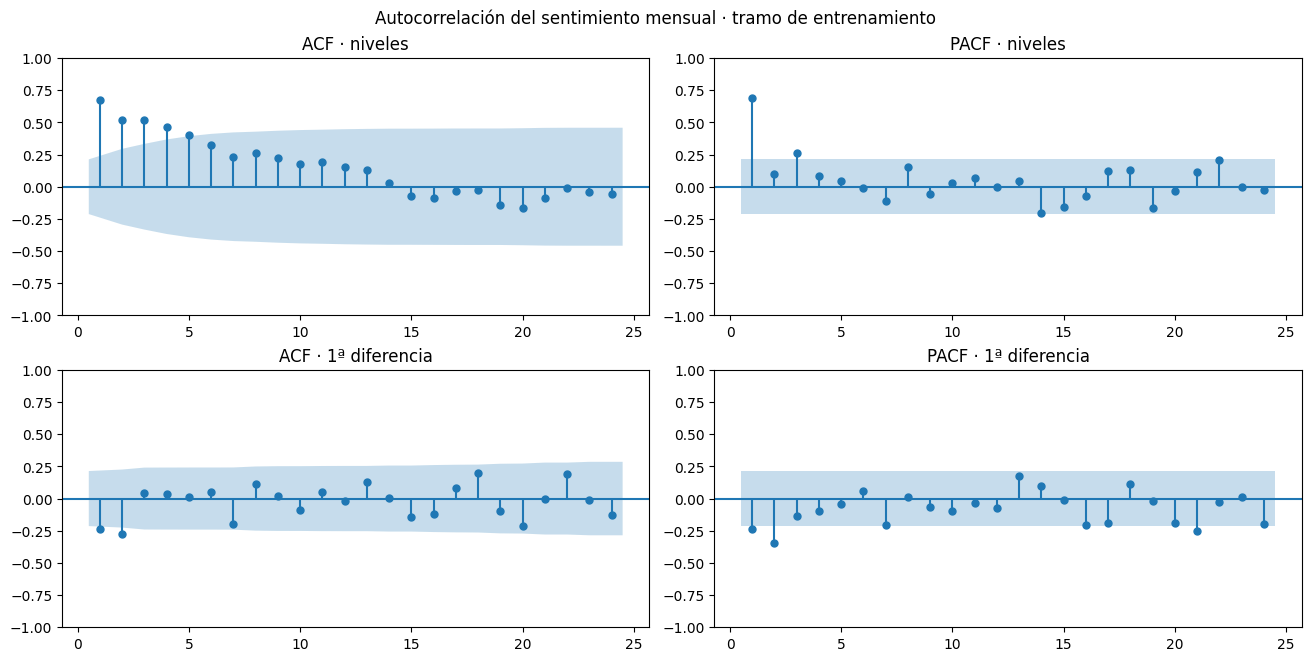

In [4]:
z = tr.interpolate()
fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), layout="constrained")
for fila, (titulo, s) in enumerate([("niveles", z), ("1ª diferencia", z.diff().dropna())]):
    plot_acf(s, lags=24, zero=False, ax=axes[fila, 0]); axes[fila, 0].set_title(f"ACF · {titulo}")
    plot_pacf(s, lags=24, zero=False, method="ols", ax=axes[fila, 1]); axes[fila, 1].set_title(f"PACF · {titulo}")
fig.suptitle("Autocorrelación del sentimiento mensual · tramo de entrenamiento")
fig.savefig(RESULTS / "03_acf_pacf_train.png", dpi=160)
plt.show()

**Lectura:**
- En niveles, la ACF decae lentamente. Es lo esperable en una serie con tendencia o con un salto de nivel (2018), y no deja claro si hay que diferenciar.
- En primera diferencia, el patrón típico es un pico negativo en el retardo 1 de la ACF, que indica un componente MA(1).
- No hay picos en los retardos 12 ni 24, lo que confirma lo visto en el notebook 02: **no se incluye componente estacional**.

Como ADF no es concluyente, se prueban **ambas opciones** en la rejilla:
- `d = 0` con constante (`c`) o con constante y tendencia lineal (`ct`).
- `d = 1` sin término (`n`) o con deriva (`t`).

En los dos casos, p, q ∈ {0, 1, 2}. AIC y BIC no son comparables entre modelos con distinta `d`, así que **la selección se hace por el RMSE en validación**, como recomiendan los apuntes.

## 3. Candidatos y selección en validación

Cada candidato se ajusta con entrenamiento y se evalúa en validación de dos formas:
- **Multipaso:** se predicen todos los meses de validación de una vez, desde el final del entrenamiento.
- **A un paso:** cada mes se predice con los datos reales hasta el mes anterior, manteniendo los parámetros del entrenamiento. Es lo que haría un analista que actualiza la predicción cada mes.

Las métricas se calculan solo sobre los meses con dato.

In [5]:
def metricas(real, pred):
    m = real.notna() & pred.notna()
    e = real[m] - pred[m]
    return {"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()), "n": int(m.sum())}

def ajustar(serie, order, trend):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")   # se registra la convergencia explícitamente abajo
        fit = SARIMAX(serie, order=order, trend=trend).fit(disp=False, maxiter=500)
    return fit

def un_paso(fit, serie_completa, inicio):
    """Predicciones a un paso con los parámetros de `fit` sobre una serie más larga (sin reestimar)."""
    res = fit.apply(serie_completa)
    return res.get_prediction(start=inicio).predicted_mean

trainval = pd.concat([train, val])
filas, fallos = [], []
for d in (0, 1):
    for p, q, trend in product(range(3), range(3), ["c", "ct"] if d == 0 else ["n", "t"]):
        try:
            fit = ajustar(train, (p, d, q), trend)
            if not fit.mle_retvals.get("converged", True):
                raise RuntimeError("no converge")
            multi = fit.forecast(len(val))
            uno = un_paso(fit, trainval, val.index[0]).loc[val.index]
            filas.append({"order": (p, d, q), "trend": trend, "AIC": fit.aic, "BIC": fit.bic,
                          **{f"{k}_multipaso": v for k, v in metricas(val, multi).items() if k != "n"},
                          **{f"{k}_1paso": v for k, v in metricas(val, uno).items() if k != "n"}})
        except Exception as exc:
            fallos.append({"order": (p, d, q), "trend": trend, "error": str(exc)})

ranking = pd.DataFrame(filas).sort_values("RMSE_multipaso").reset_index(drop=True)
ranking.to_csv(RESULTS / "03_comparativa_validacion.csv", index=False)
print(f"Candidatos válidos: {len(ranking)} · descartados: {len(fallos)}", fallos if fallos else "")
ranking.head(10).round(4)

Candidatos válidos: 34 · descartados: 2 [{'order': (1, 0, 0), 'trend': 'ct', 'error': 'no converge'}, {'order': (1, 1, 2), 'trend': 't', 'error': 'no converge'}]


,order,trend,AIC,BIC,MAE_multipaso,RMSE_multipaso,MAE_1paso,RMSE_1paso
0,"(1, 0, 2)",c,-185.4175,-173.2042,0.0409,0.0514,0.0459,0.0616
1,"(2, 0, 1)",c,-184.4905,-172.2773,0.0418,0.0515,0.0465,0.0603
2,"(1, 0, 1)",c,-185.4331,-175.6625,0.0424,0.0517,0.0466,0.0598
3,"(2, 0, 2)",c,-181.4381,-166.7822,0.0426,0.0519,0.0469,0.0601
4,"(2, 0, 0)",c,-182.5207,-172.7501,0.0468,0.0530,0.0474,0.0623
5,"(1, 0, 0)",c,-183.2874,-175.9594,0.0477,0.0537,0.0487,0.0644
6,"(0, 0, 0)",c,-150.5631,-145.6778,0.0490,0.0542,0.0490,0.0542
7,"(0, 0, 2)",c,-174.5660,-164.7954,0.0496,0.0547,0.0510,0.0646
8,"(0, 0, 1)",c,-173.3724,-166.0444,0.0498,0.0549,0.0502,0.0626
9,"(1, 1, 1)",n,-183.8800,-176.5875,0.0448,0.0628,0.0468,0.0620


**Baselines en validación.** Un modelo solo merece la pena si mejora a predicciones triviales:
- **Ingenuo:** repetir el último valor observado. En multipaso es el último mes del entrenamiento y a un paso, el mes anterior con dato.
- **Media de los últimos 12 meses** del entrenamiento.
- **Media de todo el entrenamiento.**

In [6]:
def baselines(historia, objetivo):
    """Predicciones de referencia para `objetivo` usando solo `historia` (y, a un paso, los valores previos reales)."""
    ultimo = historia.dropna().iloc[-1]
    serie = pd.concat([historia, objetivo])
    previo = serie.ffill().shift(1).loc[objetivo.index]          # último valor observado antes de cada mes
    return {
        "Ingenuo (multipaso)": pd.Series(ultimo, index=objetivo.index),
        "Ingenuo (1 paso)": previo,
        "Media últimos 12 meses": pd.Series(historia.iloc[-12:].mean(), index=objetivo.index),
        "Media del entrenamiento": pd.Series(historia.mean(), index=objetivo.index),
    }

pd.DataFrame({k: metricas(val, v) for k, v in baselines(train, val).items()}).T.round(4)

,MAE,RMSE,n
Ingenuo (multipaso),0.0729,0.0870,16.0
Ingenuo (1 paso),0.0671,0.0815,16.0
Media últimos 12 meses,0.0383,0.0564,16.0
Media del entrenamiento,0.0490,0.0542,16.0


**Criterio de selección:** el menor RMSE multipaso en validación. Si dos candidatos están muy cerca (a menos de 0,002), se prefiere el de menor BIC, por parsimonia.

In [7]:
mejor_rmse = ranking.RMSE_multipaso.min()
empatados = ranking[ranking.RMSE_multipaso <= mejor_rmse + 0.002]
elegido = empatados.sort_values("BIC").iloc[0]
ORDER, TREND = tuple(elegido.order), elegido.trend
print(f"Modelo elegido: ARIMA{ORDER} con trend='{TREND}'")
elegido.to_frame().T.round(4)

Modelo elegido: ARIMA(1, 0, 1) con trend='c'


,order,trend,AIC,BIC,MAE_multipaso,RMSE_multipaso,MAE_1paso,RMSE_1paso
2,"(1, 0, 1)",c,-185.433119,-175.662514,0.042438,0.051727,0.046596,0.059776


## 4. Evaluación final en test

Se reajusta el modelo elegido con **entrenamiento + validación** y se predice el test **una sola vez**. Se compara con los mismos baselines, calculados con la misma historia.

In [8]:
final = ajustar(trainval, ORDER, TREND)
assert final.mle_retvals.get("converged", True), "El modelo final no converge"
prediccion = final.get_forecast(len(test))
multi = prediccion.predicted_mean
ic = prediccion.conf_int(alpha=.05)
uno = un_paso(final, y, test.index[0]).loc[test.index]

resultados = {f"ARIMA{ORDER} (multipaso)": metricas(test, multi),
              f"ARIMA{ORDER} (1 paso)": metricas(test, uno),
              **{k: metricas(test, v) for k, v in baselines(trainval, test).items()}}
tabla_test = pd.DataFrame(resultados).T
tabla_test.to_csv(RESULTS / "03_metricas_test.csv")
pd.DataFrame({"real": test, "pred_multipaso": multi, "ic95_inf": ic.iloc[:, 0], "ic95_sup": ic.iloc[:, 1],
              "pred_1paso": uno}).to_csv(RESULTS / "03_predicciones_test.csv")
tabla_test.round(4)

,MAE,RMSE,n
"ARIMA(1, 0, 1) (multipaso)",0.0643,0.0716,17.0
"ARIMA(1, 0, 1) (1 paso)",0.0376,0.0451,17.0
Ingenuo (multipaso),0.0311,0.0401,17.0
Ingenuo (1 paso),0.0430,0.0506,17.0
Media últimos 12 meses,0.0532,0.0607,17.0
Media del entrenamiento,0.0687,0.0759,17.0


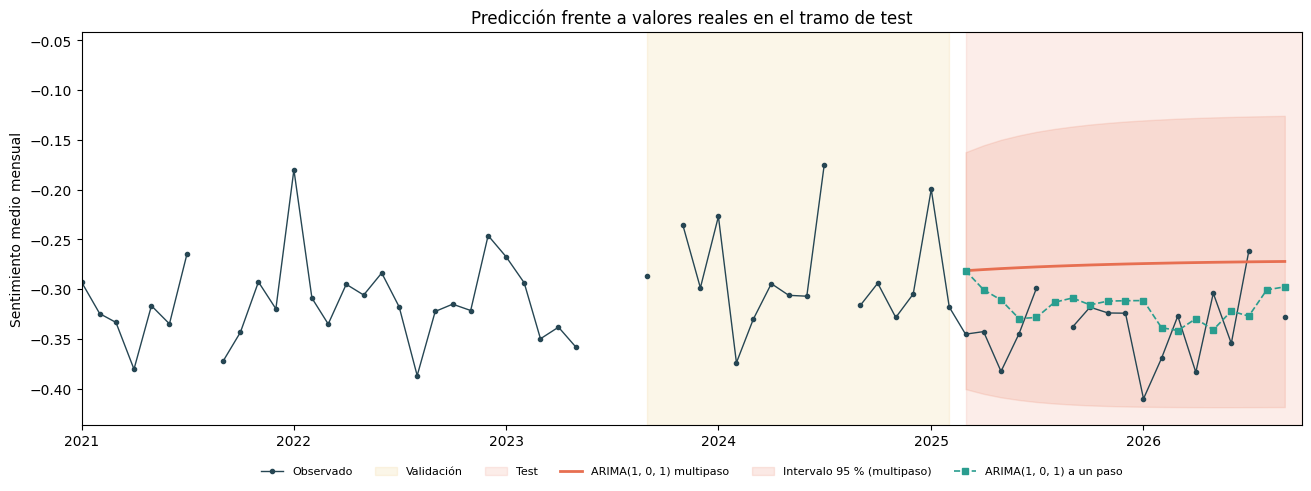

In [9]:
fig, ax = plt.subplots(figsize=(13, 4.8), layout="constrained")
ax.plot(y.index, y, "o-", color="#264653", ms=3, lw=1, label="Observado")
ax.axvspan(val.index[0], val.index[-1], color="#e9c46a", alpha=.15, label="Validación")
ax.axvspan(test.index[0], test.index[-1] + pd.offsets.MonthEnd(0), color="#e76f51", alpha=.12, label="Test")
ax.plot(multi.index, multi, color="#e76f51", lw=2, label=f"ARIMA{ORDER} multipaso")
ax.fill_between(ic.index, ic.iloc[:, 0], ic.iloc[:, 1], color="#e76f51", alpha=.15, label="Intervalo 95 % (multipaso)")
ax.plot(uno.index, uno, "s--", color="#2a9d8f", ms=4, lw=1.2, label=f"ARIMA{ORDER} a un paso")
ax.set_xlim(pd.Timestamp("2021-01-01"), y.index[-1] + pd.offsets.MonthEnd(0))
ax.set_ylabel("Sentimiento medio mensual")
ax.set_title("Predicción frente a valores reales en el tramo de test")
ax.legend(fontsize=8, ncol=6, loc="upper center", bbox_to_anchor=(.5, -.08), frameon=False)
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.savefig(RESULTS / "03_prediccion_test.png", dpi=160)
plt.show()

### Lectura de la evaluación

**Validación:** los ARIMA con `d = 0` y constante son los mejores candidatos (RMSE ≈ 0,052). Mejoran al ingenuo (0,087) y quedan a la par de la media del entrenamiento (0,054) y de la de los últimos 12 meses (0,056). Se elige ARIMA(1,0,1): su RMSE está a menos de 0,002 del mejor y tiene el menor BIC. Su AR(1) es alto (φ ≈ 0,90), lo que indica que el tono es **persistente**: un mes negativo suele ir seguido de otro negativo.

**Test:** el resultado depende del horizonte:
- **A un paso** (actualizando cada mes con el dato real), el ARIMA es el mejor método: RMSE 0,045 frente a 0,051 del ingenuo a un paso (un 11 % menos).
- **En multipaso**, el ARIMA es **peor que el ingenuo** (0,072 frente a 0,040). El motivo es estructural: un ARMA estacionario vuelve con el tiempo a su media de largo plazo, ≈ −0,27, que está influida por los años 2016–2018, más positivos. En cambio, el test (2025–2026) tiene una media de −0,34, **más negativa que cualquier periodo anterior**. Ningún modelo univariante con solo el pasado anticipa ese nivel. El ingenuo acierta porque el último dato de validación (−0,32) ya estaba cerca del nivel del test.

Es un resultado honesto y útil: **la dinámica a corto plazo sí se puede modelar, pero el nivel cambia por razones externas a la propia serie.** Es justo la motivación para añadir variables exógenas (notebook 04).

**Referencia de ruido:** con ~100 intervenciones al mes, el error de muestreo de la media mensual global es ≈ 0,29/√100 ≈ 0,03. Un RMSE de 0,045 a un paso está, por tanto, cerca del mínimo alcanzable con esta muestra.

## 5. Diagnóstico de residuos

Si el modelo recoge bien la dinámica, sus residuos deberían parecerse a ruido blanco: media cero, varianza estable y sin autocorrelación. Se revisa con:
- los gráficos de diagnóstico de statsmodels;
- **Ljung-Box**, con H0: no hay autocorrelación conjunta hasta el retardo indicado. p ≥ 0,05 significa que no se detecta autocorrelación, no que se demuestre su ausencia.

Residuos: media -0.024, desv. típica 0.923, n=103


,lb_stat,lb_pvalue
6,2.3162,0.6778
12,5.8462,0.8280


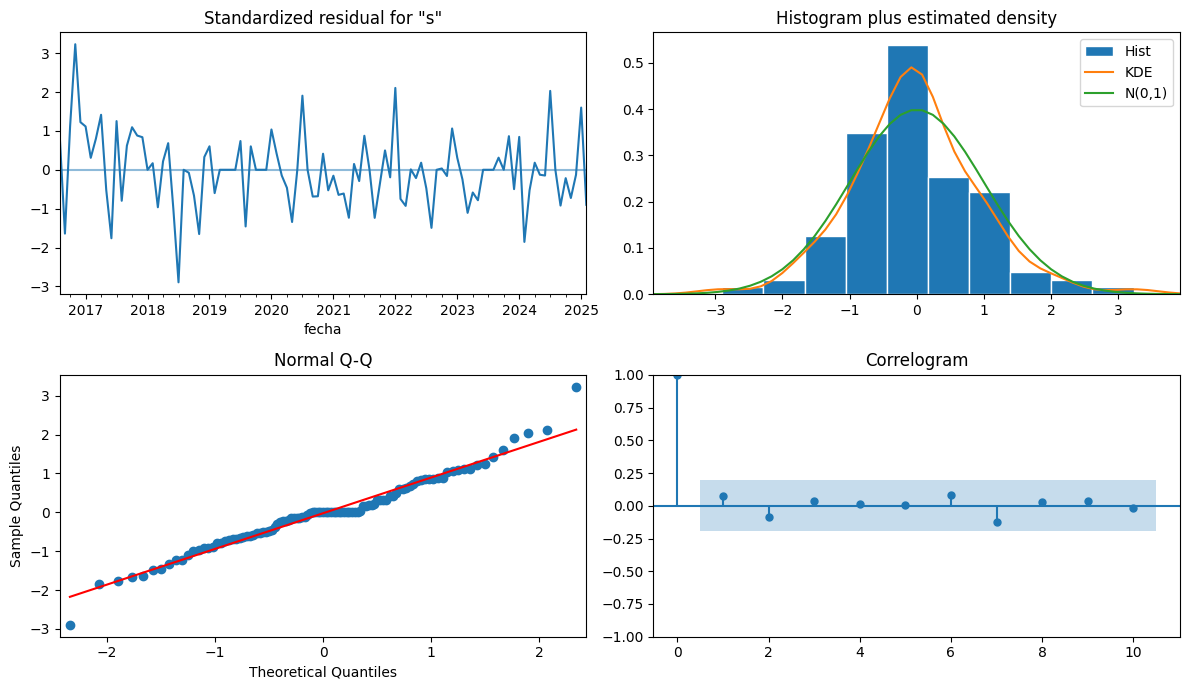

                               SARIMAX Results                                
Dep. Variable:              sentiment   No. Observations:                  103
Model:               SARIMAX(1, 0, 1)   Log Likelihood                 119.111
Date:                Tue, 24 Nov 2026   AIC                           -230.222
Time:                        19:22:05   BIC                           -219.683
Sample:                    08-01-2016   HQIC                          -225.954
                         - 02-01-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -0.0275      0.018     -1.552      0.121      -0.062       0.007
ar.L1          0.8984      0.067     13.483      0.000       0.768       1.029
ma.L1         -0.5809      0.144     -4.039      0.0

In [10]:
resid = pd.Series(final.filter_results.standardized_forecasts_error[0], index=trainval.index)
resid = resid.iloc[final.loglikelihood_burn:].dropna()
gl = ORDER[0] + ORDER[2]
ljung = acorr_ljungbox(resid, lags=[6, 12], model_df=gl, return_df=True)
print(f"Residuos: media {resid.mean():.3f}, desv. típica {resid.std():.3f}, n={len(resid)}")
display(ljung.round(4))
fig = final.plot_diagnostics(figsize=(12, 7))
fig.tight_layout(); fig.savefig(RESULTS / "03_residuos.png", dpi=160)
plt.show()
(RESULTS / "03_modelo_summary.txt").write_text(str(final.summary()), encoding="utf-8")
print(final.summary())

**Lectura de los residuos:**
- **Sin autocorrelación:** Ljung-Box da p = 0,68 (retardo 6) y p = 0,83 (retardo 12), así que el ARIMA(1,0,1) recoge la dependencia temporal.
- **Varianza no constante:** el contraste de heterocedasticidad da p = 0,03. La varianza disminuye con el tiempo, probablemente porque los meses recientes tienen más intervenciones y medias más estables.
- **Colas algo más gruesas de lo normal:** Jarque-Bera da p = 0,01, por los meses atípicos detectados en el notebook 02.

Ninguno de estos dos últimos puntos invalida las predicciones puntuales, pero hacen que los intervalos de confianza sean orientativos.

## 6. Conclusiones del modelado

La interpretación con los valores concretos se recoge en la explicación de este paso y se trasladará a `analysis.md`. Lo que se lleva al notebook 04:
- **El orden ARIMA elegido** sirve como estructura base de los errores en los SARIMAX por partido.
- **La magnitud del error** (MAE y RMSE frente al ruido mensual de ~0,04–0,06 del notebook 02) indica cuánto del movimiento mes a mes es predecible y cuánto es ruido de muestreo.